# Multimodal Product Classification on the Rakuten France Catalogue

## Report 1, Data Exploration, Visualization and Pre-processing

**Project:** Rakuten France Multimodal Product Classification  
**Authors:** wahaj Aslam, Bernhard Quehl

---

## Executive Summary

Online sellers provide product information in different formats and levels of detail. Descriptions may be short, missing or poorly formatted. Images can provide extra information.

Each Rakuten product has a `designation`, an optional `description`, an image and a target class called `prdtypecode`.

This report examines the classes, missing data, text, images and data quality before modelling begins.

# 1. Introduction

In this project, the goal is to predict the `prdtypecode` of a product using both its textual information and its image.

Manual product categorisation is slow and difficult to scale. Automatic classification can support catalogue organisation, search and recommendations.

The data is noisy. Text length and quality vary, descriptions can be missing, and similar images can belong to different classes. We will compare text, images and their combination.

Using text and images makes this a **multimodal classification problem**.

The report examines:

- how the product classes are distributed
- whether important information is missing
- how much text is normally available
- whether product classes use different vocabulary
- whether product classes can be distinguished visually

The official measure is the **weighted F1-score**. The published benchmarks scored **0.8113** with designation text and **0.5534** with images.

# 2. Dataset Overview

## 2.1 Loading the data

Rakuten France provided the data for the challenge.
The data contains **84916 training products** and **13812 test products**. This report uses the labelled training data. The test data is kept for modelling.

In [352]:
from pathlib import Path

import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image
from scipy import stats
from IPython.display import display
from src.data_utils import load_merged_data, load_raw_data, get_image_path
plt.style.use("seaborn-v0_8-whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)

print("Environment and data_utils loaded successfully.")

df = load_merged_data()

# Data structure
print("Dataset Shape",df.shape)
df.head(4)

Environment and data_utils loaded successfully.
Dataset Shape (84916, 5)


,designation,description,productid,imageid,prdtypecode
0,Olivia: Personalisiertes Notizbuch / 150 Seiten / Punktraster / Ca Din A5 / Rosen-Design,NaN,3804725264,1263597046,10
1,Journal Des Arts (Le) N° 133 Du 28/09/2001 - L'art Et Son Marche Salon D'art Asiatique A Paris - Jacques Barrere - Francois Perrier - La Reforme Des Ventes Aux Encheres Publiques - Le Sna Fete Ses Cent Ans.,NaN,436067568,1008141237,2280
2,Grand Stylet Ergonomique Bleu Gamepad Nintendo Wii U - Speedlink Pilot Style,PILOT STYLE Touch Pen de marque Speedlink est 1 stylet ergonomique pour GamePad Nintendo Wii U.<br> Pour un confort optimal et une précision maximale sur le GamePad de la Wii U: ce grand stylet hautement ergonomique est non seulement parfaitement...,201115110,938777978,50
3,Peluche Donald - Europe - Disneyland 2000 (Marionnette À Doigt),NaN,50418756,457047496,1280


## 2.2 Available variables

The dataset contains five variables:

| Variable | Description |
|---|---|
| `designation` | The short name of the product |
| `description` | A longer description of the product |
| `productid` | A unique identifier for the product |
| `imageid` | The identifier of the product image |
| `prdtypecode` | The product category and the target variable to predict |

Although `productid`, `imageid`, and `prdtypecode` are stored as numbers, they are identifiers or category labels rather than numerical measurements. Their numerical values and the distances between them have no meaningful interpretation. The `description` column also contains many missing values, while some non-missing descriptions include HTML tags or encoded HTML characters. These issues will be addressed during preprocessing.

In [353]:
df.info()

print("\nNumber of product classes:", df["prdtypecode"].nunique())

<class 'pandas.DataFrame'>
RangeIndex: 84916 entries, 0 to 84915
Data columns (total 5 columns):
 #   Column       Non-Null Count  Dtype
---  ------       --------------  -----
 0   designation  84916 non-null  str  
 1   description  55116 non-null  str  
 2   productid    84916 non-null  int64
 3   imageid      84916 non-null  int64
 4   prdtypecode  84916 non-null  int64
dtypes: int64(3), str(2)
memory usage: 52.5 MB

Number of product classes: 27


## 2.3 Individual product investigation

Before analysing thousands of observations together, it is useful to inspect a few products directly.

### Initial observation

As noted above after loading and viewing the data, each row represents one product and includes a designation, a description, product and image IDs, and a product category code. An initial inspection shows that many products have missing descriptions (`NaN`). Some of the available descriptions also contain HTML tags or encoded HTML characters, such as `</p>, &amp;#39;`. These issues will need to be handled during text preprocessing.

# 3. Target Variable Analysis

The target variable, `prdtypecode`, contains 27 product classes (as calculated above). We examine the number of products in each class to see whether the dataset is balanced. Large differences in class counts could make the model perform better on common categories with a bias and struggle with less represented ones.

In [354]:
class_counts = (df["prdtypecode"].value_counts().sort_values())
print(class_counts[10:17])
print("Largest class:", class_counts.max())
print("Smallest class:", class_counts.min())
print("Largest / smallest ratio:", round(class_counts.max() / class_counts.min(), 2))

prdtypecode
2585    2496
40      2508
2582    2589
1140    2671
2705    2761
10      3116
1320    3241
Name: count, dtype: int64
Largest class: 10209
Smallest class: 764
Largest / smallest ratio: 13.36


## Figure 1, Number of products per `prdtypecode`

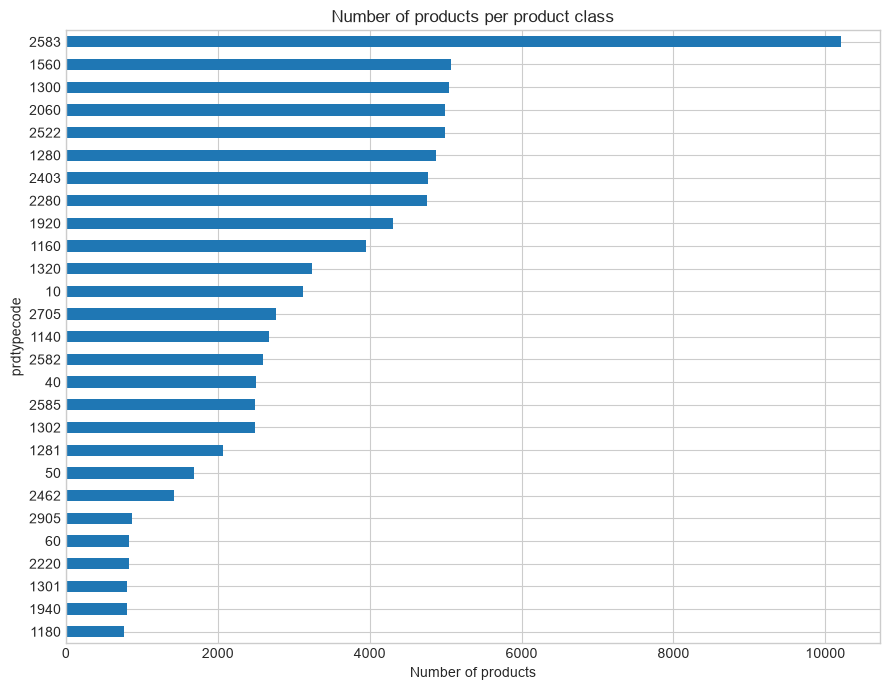

In [355]:
plt.figure(figsize=(9, 7))
class_counts.plot(kind="barh")
plt.title("Number of products per product class")
plt.xlabel("Number of products")
plt.ylabel("prdtypecode")
plt.tight_layout()
plt.show()

### Analysis

Figure 1 shows that the 27 product classes are not evenly represented. The largest class contains 10209 products, while the smallest contains 764.

A model may learn the larger classes more easily. The data split should preserve class proportions, and performance should be checked for every class.

# 4. Missing Data

The next step is to understand how complete the dataset is.

In [356]:
missing = pd.DataFrame({
    "Missing values": df.isna().sum(),
    "Missing (%)": (df.isna().mean() * 100).round(2),
})

display(missing.sort_values("Missing (%)", ascending=False))

,Missing values,Missing (%)
description,29800,35.09
designation,0,0.00
productid,0,0.00
imageid,0,0.00
prdtypecode,0,0.00


In [357]:
# compare missing descriptions across product classes.
df["description_missing"] = df["description"].isna()

We also compare the missing-description rate across product classes.

## Figure 2, Missing descriptions by product class

Lowest missing rate: class 2905 (0.00%)
Highest missing rate: class 2403 (97.36%)


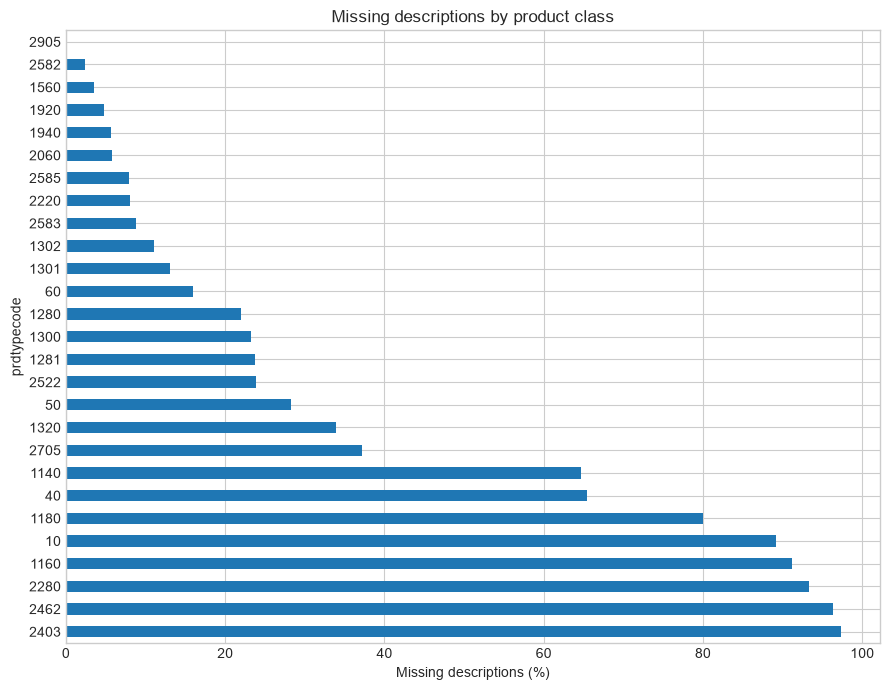

In [358]:
missing_by_class = (df.groupby('prdtypecode')['description_missing'].mean() * 100).sort_values(ascending=False)
print(f"Lowest missing rate: class {missing_by_class.idxmin()} "f"({missing_by_class.min():.2f}%)")
print(f"Highest missing rate: class {missing_by_class.idxmax()} "f"({missing_by_class.max():.2f}%)")

plt.figure(figsize=(9, 7))
missing_by_class.plot(kind="barh")
plt.title("Missing descriptions by product class")
plt.xlabel("Missing descriptions (%)")
plt.ylabel("prdtypecode")
plt.tight_layout()
plt.show()

### Analysis

Descriptions are missing for **35.09%** of the products overall.

The chart shows a large difference between product classes. Class `2905` has no missing descriptions, while **97.36%** of the descriptions in class `2403` are missing.

Because many products do not have a description, the classification model cannot rely on this field alone. These products should be kept, with missing descriptions handled consistently during preprocessing.

# 5. Text Exploration

The Rakuten dataset contains two main text fields:

- `designation`
- `description`

We count the words in each text field and compare their lengths across product classes.

In [359]:
df["designation_words"] = (df["designation"].fillna("").str.split().str.len())
df["description_words"] = (df["description"].fillna("").str.split().str.len())
print(df[["designation_words", "description_words"]].describe(percentiles=[0.5, 0.75, 0.90, 0.95, 0.99]))

       designation_words  description_words
count       84916.000000       84916.000000
mean           11.557374          80.166635
std             6.207966         115.411284
min             3.000000           0.000000
50%            11.000000          35.000000
75%            14.000000         125.000000
90%            18.000000         213.000000
95%            22.000000         291.000000
99%            38.000000         511.000000
max            56.000000        2068.000000


## 5.1 Designation length

We noticed in the missing data that the `designation` is available for every product, so it can be the most consistent source of text in the dataset. We can examine its length to see how much information is usually provided and how much this varies between products.
### Figure 3, Distribution of designation length

Observed range: 3 to 56 words
25th percentile: 7, median: 11, 75th percentile: 14 words
99% of designations contain 38 words or fewer


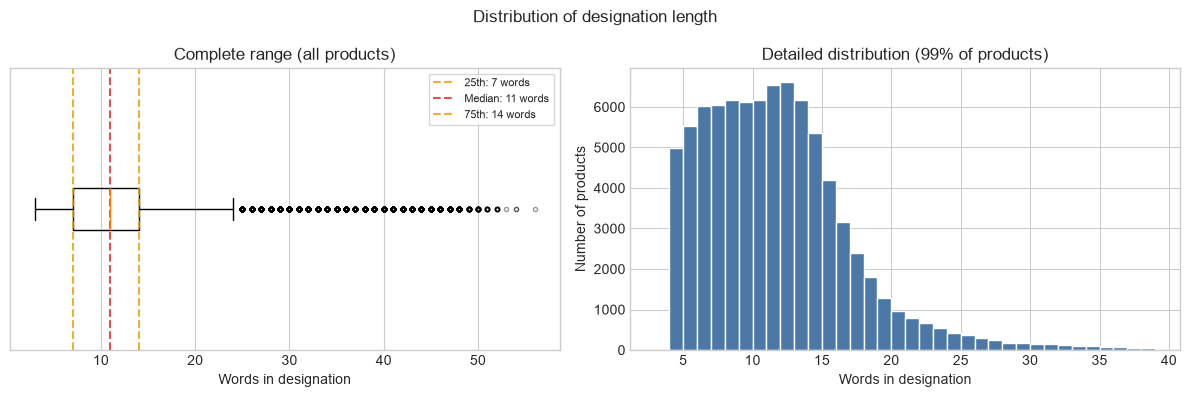

In [360]:
min_words = int(df["designation_words"].min())
max_words = int(df["designation_words"].max())
q1_words = int(df["designation_words"].quantile(0.25))
median_words = int(df["designation_words"].median())
q3_words = int(df["designation_words"].quantile(0.75))
p99_words = int(df["designation_words"].quantile(0.99))

print(f"Observed range: {min_words} to {max_words} words")
print(f"25th percentile: {q1_words}, median: {median_words}, "f"75th percentile: {q3_words} words")
print(f"99% of designations contain {p99_words} words or fewer")

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].boxplot(df["designation_words"], orientation="horizontal",flierprops={"markersize": 3, "alpha": 0.4},)

percentile_labels = [
    (q1_words, "25th", "#E59F00"),
    (median_words, "Median", "#D62728"),
    (q3_words, "75th", "#E59F00"),
]

for value, label, color in percentile_labels:
    axes[0].axvline(
        value,
        color=color,
        linestyle="--",
        alpha=0.8,
        label=f"{label}: {value} words",
    )

axes[0].set_title("Complete range (all products)")
axes[0].set_xlabel("Words in designation")
axes[0].set_yticks([])
axes[0].legend(loc="upper right", fontsize=8, frameon=True)

central_lengths = df.loc[df["designation_words"] <= p99_words,"designation_words",]

axes[1].hist(
    central_lengths,
    bins=range(min_words, p99_words + 2),
    color="#4C78A8",
    edgecolor="white",
)
axes[1].set_title("Detailed distribution (99% of products)")
axes[1].set_xlabel("Words in designation")
axes[1].set_ylabel("Number of products")

fig.suptitle("Distribution of designation length")
plt.tight_layout()
plt.show()

### Analysis

The complete distribution ranges from **3 to 56 words**. The median designation contains **11 words**, and the middle 50% contain between **7 and 14 words**.
The first plot summarizes all products and shows the complete range, including the longest designations. The second plot gives a more detailed view of the range containing 99% of the products.

## 5.2 Designation length by product class

Next, we compare designation length across the 27 classes.

### Figure 4, Designation length by `prdtypecode`

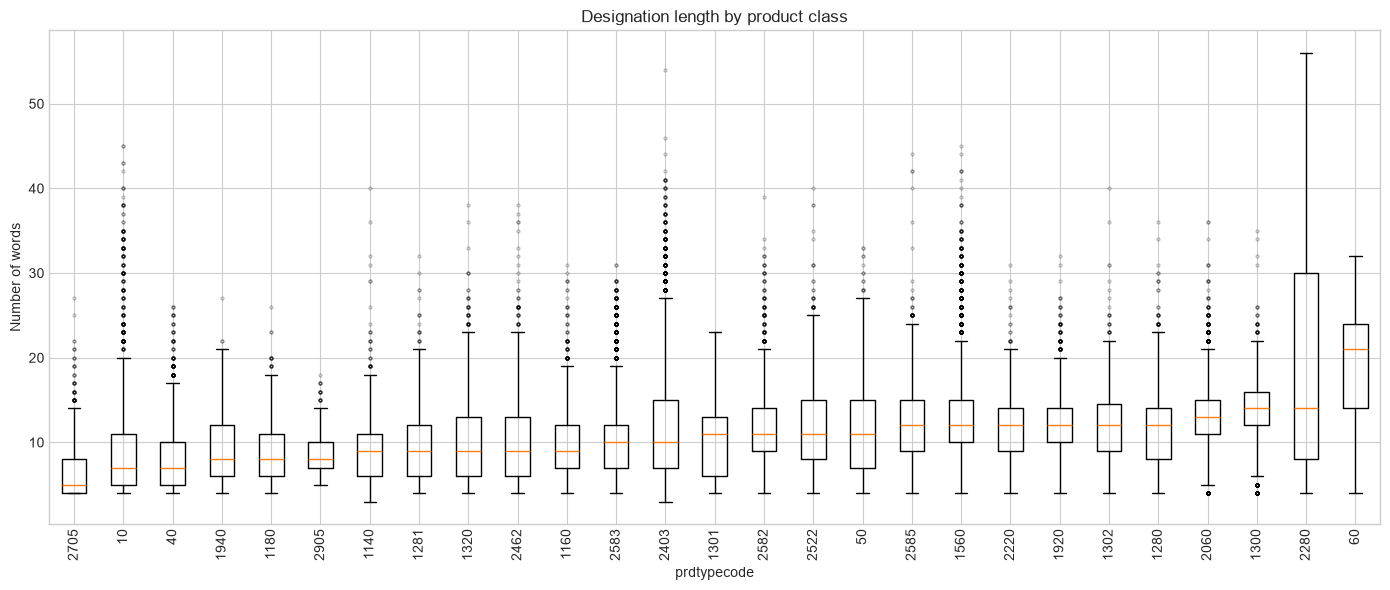

prdtypecode
2705     5.0
10       7.0
40       7.0
1940     8.0
1180     8.0
2905     8.0
1140     9.0
1281     9.0
1320     9.0
2462     9.0
1160     9.0
2583    10.0
2403    10.0
1301    11.0
2582    11.0
2522    11.0
50      11.0
2585    12.0
1560    12.0
2220    12.0
1920    12.0
1302    12.0
1280    12.0
2060    13.0
1300    14.0
2280    14.0
60      21.0
Name: designation_words, dtype: float64


In [361]:
designation_class_order = (df.groupby("prdtypecode")["designation_words"].median().sort_values().index)
designation_values = [df.loc[df["prdtypecode"] == code,"designation_words",] for code in designation_class_order]

plt.figure(figsize=(14, 6))
plt.boxplot(designation_values,tick_labels=designation_class_order,flierprops={"markersize": 2, "alpha": 0.25},)
plt.xticks(rotation=90)
plt.title("Designation length by product class")
plt.xlabel("prdtypecode")
plt.ylabel("Number of words")
plt.tight_layout()
plt.show()

designation_medians = (df.groupby("prdtypecode")["designation_words"].median().sort_values())
print(designation_medians)

### Analysis

Median designation length ranges from **5 words** in class `2705` to **21 words** in class `60`.

The distributions overlap, so length alone cannot separate all 27 classes. We also need to examine the words used in each class.

# 6. Description Length

Descriptions can provide additional information beyond the designation, but they are not available for every product. We examine the length of the available descriptions to understand how much extra text they provide and whether this differs across product classes.

### Figure 5, Description length by `prdtypecode`

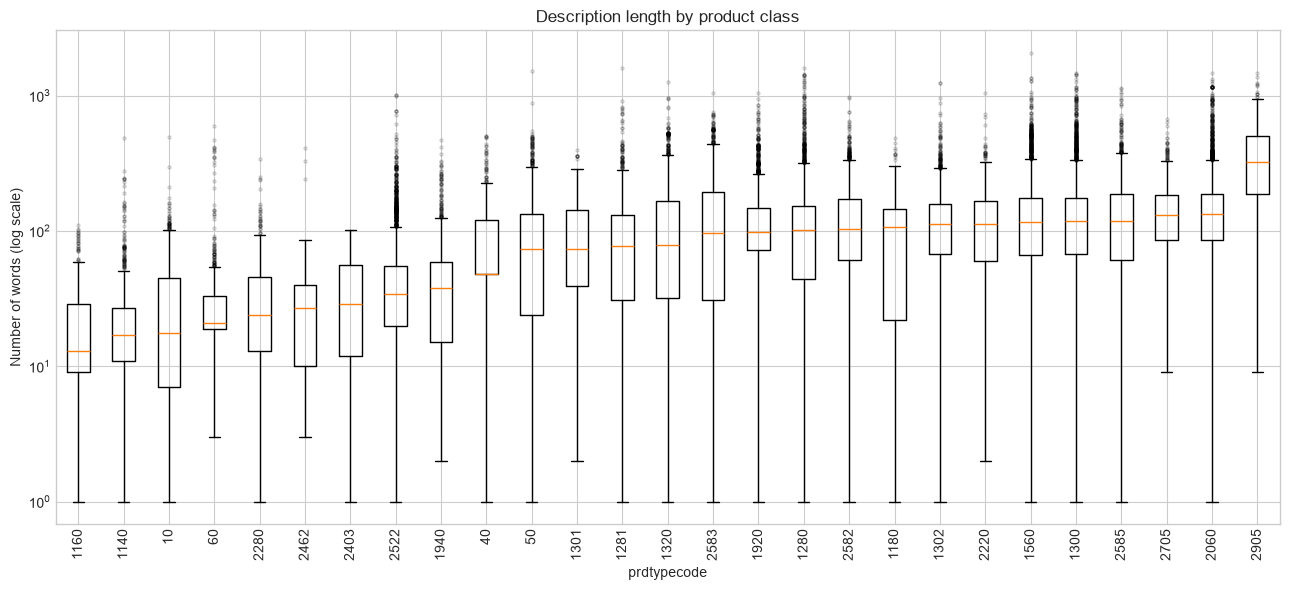

In [362]:
available_descriptions = df.loc[df["description_words"] > 0].copy()
description_class_order = (available_descriptions.groupby("prdtypecode")["description_words"].median().sort_values().index)
description_values = [available_descriptions.loc[available_descriptions["prdtypecode"] == code,"description_words"]
    for code in description_class_order
]

plt.figure(figsize=(13, 6))
plt.boxplot(description_values, tick_labels=description_class_order, flierprops={"markersize": 2, "alpha": 0.2},)

plt.yscale("log") #the very long descriptions stretched the axis so much that most box plots near the bottom became hard to compare.
plt.xticks(rotation=90)
plt.title("Description length by product class")
plt.xlabel("prdtypecode")
plt.ylabel("Number of words (log scale)")

plt.tight_layout()
plt.show()

In [363]:
description_stats = (available_descriptions.groupby("prdtypecode")["description_words"]
    .agg(["median", "mean", "max"])
    .sort_values("median")
)

print(description_stats)

             median        mean   max
prdtypecode                          
1160           13.0   22.833811   110
1140           17.0   25.069841   486
10             17.5   37.381657   491
60             21.0   35.586552   593
2280           24.0   38.562500   339
2462           27.0   44.075472   409
2403           29.0   36.428571   102
2522           34.0   50.627895  1015
1940           38.0   53.786280   466
40             48.0   84.519630   504
50             73.0  100.440664  1525
1301           74.0   92.481481   395
1281           77.0   98.500000  1596
1320           79.0  117.172430  1265
2583           96.0  125.095637  1049
1920           98.0  120.819092  1052
1280          101.0  125.961336  1607
2582          104.0  129.985358   980
1180          107.0  112.189542   485
1302          112.0  126.004968  1243
2220          112.0  124.469657  1047
1560          117.0  145.401961  2068
1300          118.0  152.546488  1470
2585          118.0  139.671889  1134
2705        

### Analysis

Description length varies greatly between product classes. The median ranges from **13 words** in class `1160` to **323 words** in class `2905`.

Some classes contain much more description text than others. The box plots overlap, so description length alone cannot identify a class.

Only products with a description are included. The logarithmic scale makes the full range of **1 to 2068 words** easier to see; it does not remove or change any descriptions.

## 6.1 Description text

Long descriptions use more memory and processing time. We compare several word limits without changing the data. Missing descriptions are excluded.

The value **34** is included only as a reference because the challenge benchmark used 34 words for the shorter `designation` field. 

For each limit, we answer two different questions:

1. **How many descriptions fit completely?** 
2. **How much of all description text is kept?**

For example, suppose three descriptions contain 50, 100, and 300 words. With a 100-word limit, two of the three descriptions fit completely. The model could keep 50 + 100 + 100 = 250 of the original 450 words.

### Figure 6, Description coverage at different word limits

,Word limit,Descriptions fitting completely,Descriptions needing shortening,Descriptions fitting completely (%),Description words kept (%)
0,34,12324,42792,22.36,24.58
1,64,20189,34927,36.63,41.68
2,128,34630,20486,62.83,67.55
3,256,49264,5852,89.38,88.47
4,512,54270,846,98.47,97.46


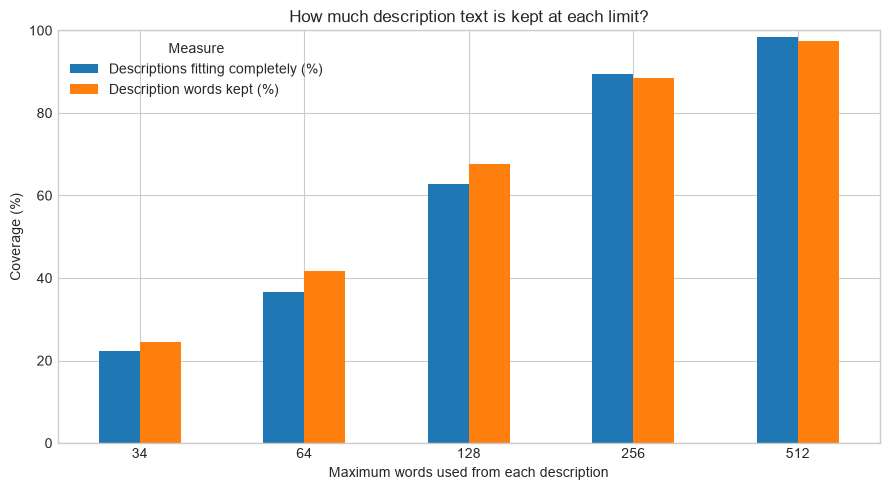

In [364]:
available_description_lengths = df.loc[
    df["description_words"] > 0,
    "description_words",
]

candidate_limits = [34, 64, 128, 256, 512]
coverage_rows = []

number_of_descriptions = len(available_description_lengths)
total_original_words = available_description_lengths.sum()

for word_limit in candidate_limits:
    fits_completely = available_description_lengths <= word_limit
    words_kept_per_description = available_description_lengths.apply(
        lambda word_count: min(word_count, word_limit)
    )

    coverage_rows.append({
        "Word limit": word_limit,
        "Descriptions fitting completely": int(fits_completely.sum()),
        "Descriptions needing shortening": int((~fits_completely).sum()),
        "Descriptions fitting completely (%)": (
            fits_completely.sum() / number_of_descriptions * 100
        ),
        "Description words kept (%)": (
            words_kept_per_description.sum() / total_original_words * 100
        ),
    })

text_coverage = pd.DataFrame(coverage_rows)
text_coverage[
    ["Descriptions fitting completely (%)", "Description words kept (%)"]
] = text_coverage[
    ["Descriptions fitting completely (%)", "Description words kept (%)"]
].round(2)

display(text_coverage)

plot_data = text_coverage.set_index("Word limit")[
    ["Descriptions fitting completely (%)", "Description words kept (%)"]
]

plot_data.plot(kind="bar", figsize=(9, 5))
plt.ylim(0, 100)
plt.xlabel("Maximum words used from each description")
plt.ylabel("Coverage (%)")
plt.title("How much description text is kept at each limit?")
plt.xticks(rotation=0)
plt.legend(title="Measure")
plt.tight_layout()
plt.show()

### Analysis

The 34-word limit used for designations in the challenge benchmark would be too short for most descriptions: only **22.36%** would fit completely, and only **24.58%** of all description words would be kept.

With a limit of **128 words**, **62.83%** of descriptions would fit completely and **67.55%** of all description words would be kept. The remaining **20486 descriptions** are longer than this limit.

With a limit of **256 words**, **89.38%** of descriptions would fit completely and **88.47%** of all description words would be kept. Only **5852 descriptions** are longer than this limit.

No description is actually shortened here. This is only a comparison of possible limits. It measures the amount of text retained, but it does not tell us whether the removed words contain useful classification information. These values use the raw text and may change after preprocessing.

## 6.2 Relationship between designation and description length

We check whether longer designations also have longer descriptions. Products without a description are excluded.

### Figure 7, Designation and description length

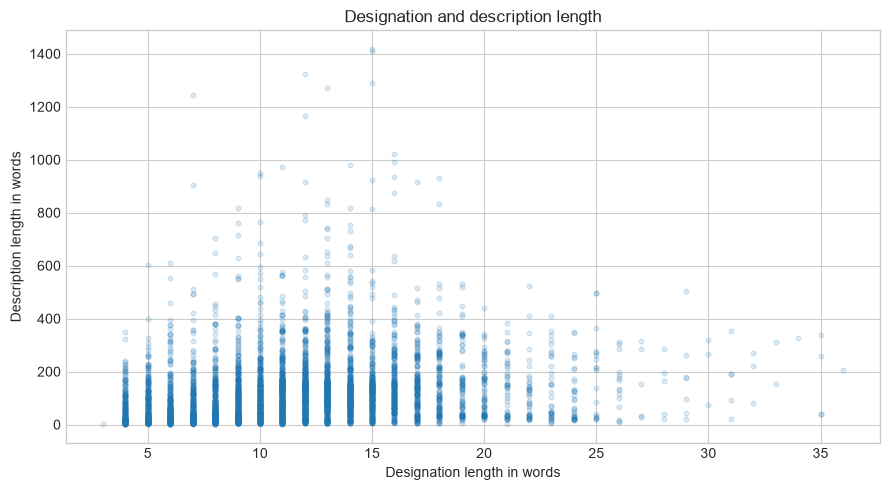

Spearman correlation: 0.265
Products included: 55116


In [365]:
text_lengths = df.loc[df["description_words"] > 0, ["designation_words", "description_words"]]
plot_sample = text_lengths.sample(min(5000, len(text_lengths)), random_state=42)

plt.figure(figsize=(9, 5))
plt.scatter(plot_sample["designation_words"], plot_sample["description_words"], alpha=0.15, s=12)
plt.xlabel("Designation length in words")
plt.ylabel("Description length in words")
plt.title("Designation and description length")
plt.tight_layout()
plt.show()

correlation, p_value = stats.spearmanr(text_lengths["designation_words"], text_lengths["description_words"])
print(f"Spearman correlation: {correlation:.3f}")
print(f"Products included: {len(text_lengths)}")

### Analysis

The Spearman correlation is **0.265**. This is a weak positive relationship.

Longer designations sometimes have longer descriptions, but the pattern is weak. The two fields should be tested separately and together.

# 7. Vocabulary Analysis

Text length tells us how much information is available, but not whether the actual words help distinguish product types.

The vocabulary is too large to inspect manually. TF-IDF gives a short list of the highest-scoring words in each class.

In [366]:
# combined text from designation and description
df["text"] = (df["designation"].fillna("")+ " "+ df["description"].fillna(""))

## 7.1 Raw frequent terms

Before filtering any words, we inspect the most common terms in the raw text. This is a data-quality check which can reveal common French grammar words, HTML fragments that we noticed for randomly selected observations, or encoded-character noise that should be considered during preprocessing.

In [384]:
from sklearn.feature_extraction.text import CountVectorizer

raw_vectorizer = CountVectorizer(lowercase=True,min_df=5,)
raw_counts = raw_vectorizer.fit_transform(df["text"])
raw_terms = raw_vectorizer.get_feature_names_out()
raw_frequencies = np.asarray(raw_counts.sum(axis=0)).ravel()

top_raw_terms = pd.DataFrame({"Term": raw_terms, "Count": raw_frequencies,}).sort_values("Count", ascending=False).head(20)

display(top_raw_terms)

,Term,Count
12573,de,415957
2377,39,168959
21645,la,162313
15679,et,154421
8226,br,123832
22104,li,109071
28157,pour,100153
15030,en,96219
21927,le,95830
22047,les,80931


### Observation

The raw results are dominated by common French words such as `de`, `la`, `et`, and `pour`. They also reveal formatting noise such as `br`, `li`, `strong`, and `39`.

## 7.2 Category-focused vocabulary

For the next view, we ignore the common French grammar words to analyse product related words.

In [368]:
FRENCH_STOPWORDS = [
    "le", "la", "les", "un", "une",
    "des", "de", "du", "et", "ou",
    "en", "dans", "avec", "pour",
    "sur", "par", "au", "aux",
    "ce", "ces", "cette",
    "br", "li", "39",  
]

`FRENCH_STOPWORDS` contains common French words identified in the raw vocabulary check. The list is used only for this TF-IDF view; it does not remove anything from the dataset.

The function below examines one product class at a time. It calculates the average TF-IDF score of every word in that class, sorts the scores, and returns the highest-scoring words. These words are common or important within the class, but they are not necessarily unique to it.

In [369]:
from sklearn.feature_extraction.text import TfidfVectorizer

tfidf = TfidfVectorizer(
    lowercase=True,
    stop_words=FRENCH_STOPWORDS,
    min_df=5,
    max_df=0.90,
    max_features=20000
)

X_tfidf = tfidf.fit_transform(df["text"])
terms = np.array(tfidf.get_feature_names_out())

print("Vocabulary size:", len(terms))
print("TF-IDF matrix shape:", X_tfidf.shape)

Vocabulary size: 20000
TF-IDF matrix shape: (84916, 20000)


In [370]:
def top_terms_for_class(class_code, number_of_terms=10):
    """Return the words with the highest average TF-IDF score in one class."""

    rows_in_class = (df["prdtypecode"] == class_code).to_numpy()
    class_tfidf = X_tfidf[rows_in_class]
    average_score_per_word = np.asarray(class_tfidf.mean(axis=0)).ravel()
    top_word_positions = (average_score_per_word.argsort()[::-1][:number_of_terms])
    
    return pd.DataFrame({
        "Word": terms[top_word_positions],
        "Average TF-IDF score": average_score_per_word[top_word_positions],
    })

In [371]:
# Example: show the 10 highest-scoring words in class 1280.
top_terms_for_class(1280)

,Word,Average TF-IDF score
0,enfants,0.046161
1,doudou,0.032835
2,peluche,0.030466
3,jouet,0.027964
4,jouets,0.025146
5,bébé,0.021913
6,puzzle,0.021860
7,toy,0.020068
8,poupée,0.018894
9,and,0.017388


## Figure 8, Highest average TF-IDF words in each class

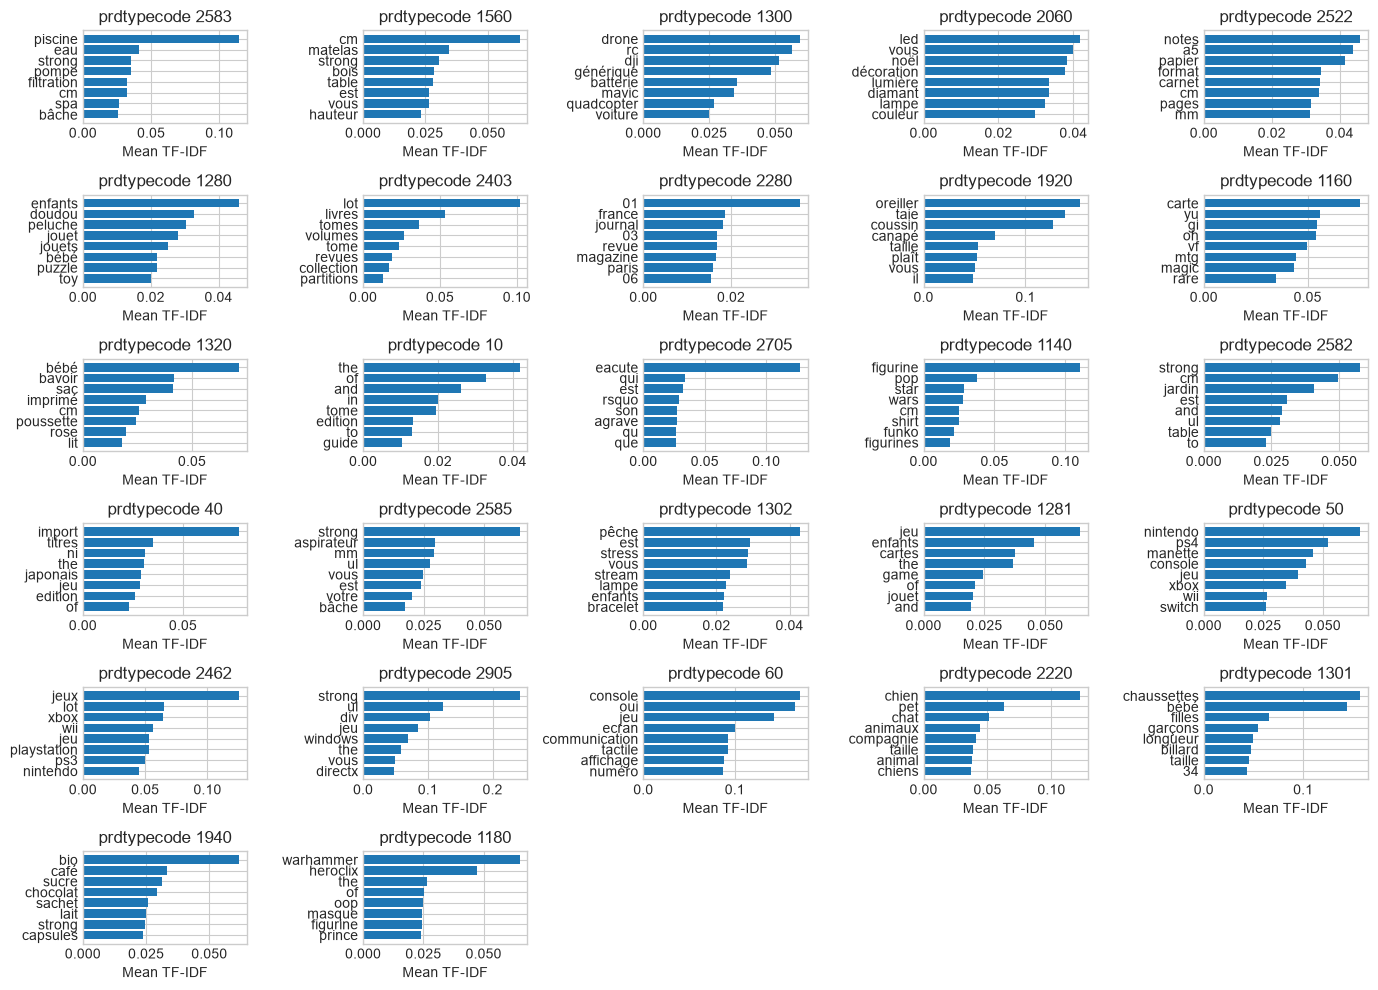

In [372]:
selected_codes = (df["prdtypecode"].value_counts().head(27).index.tolist())

fig, axes = plt.subplots(6, 5,figsize=(14, 10))

axes = axes.flatten()

for ax, code_value in zip(axes, selected_codes):
    top_words = top_terms_for_class(code_value, number_of_terms=8,)
    ax.barh(top_words["Word"][::-1], top_words["Average TF-IDF score"][::-1],)
    ax.set_title(f"prdtypecode {code_value}")
    ax.set_xlabel("Mean TF-IDF")

# hide the three unused panels in the 6 × 5 grid.
for ax in axes[len(selected_codes):]:
    ax.axis("off")

plt.tight_layout()
plt.show()

### Analysis

The raw vocabulary table showed something interesting where the description seems to be dominated by common French words such as `de`, `la`, and `et`. It also contains terms such as `br`, `li`, `strong`, and `39`, which come from HTML or encoded text. This confirms that text cleaning will be needed before modelling.

After common French words are ignored for a quick analysis, Figure 8 shows clearer product-related vocabulary. For example, class `2583` contains terms such as `piscine`, `eau`, `pompe`, and `filtration`, class `1300` contains `drone`, `dji`, `batterie`, and `mavic`; and class `2522` contains `papier`, `carnet`, `pages`, and `a5`.

HTML-related terms still appear in some classes because this analysis uses the raw text. The stopword list removes common French words from this TF-IDF view.

The classes use different product words, which supports testing a text model.

# 8. Image Exploration

Each product is linked to an image. Images can provide useful information about the shape, colour, or appearance of the product that is not always clear from its text.

We first check that every row has a matching image file. We then look at a random sample from the six largest product classes to see whether the images show useful class patterns.

In [373]:
df["image_path"] = df.apply(lambda row: Path(get_image_path(row["imageid"], row["productid"])),axis=1)

df["image_exists"] = df["image_path"].apply(Path.exists)

available_images = int(df["image_exists"].sum())
missing_images = int((~df["image_exists"]).sum())
available_percentage = available_images / len(df) * 100

print(f"Available images: {available_images} ({available_percentage:.2f}%)")
print(f"Missing images: {missing_images}")

Available images: 84916 (100.00%)
Missing images: 0


## 8.1 Looking at images by class

The grid below shows some randomly selected images from each of the six largest classes. Random sampling gives a more honest view than choosing only clear examples.

### Figure 9, Random image samples from product classes

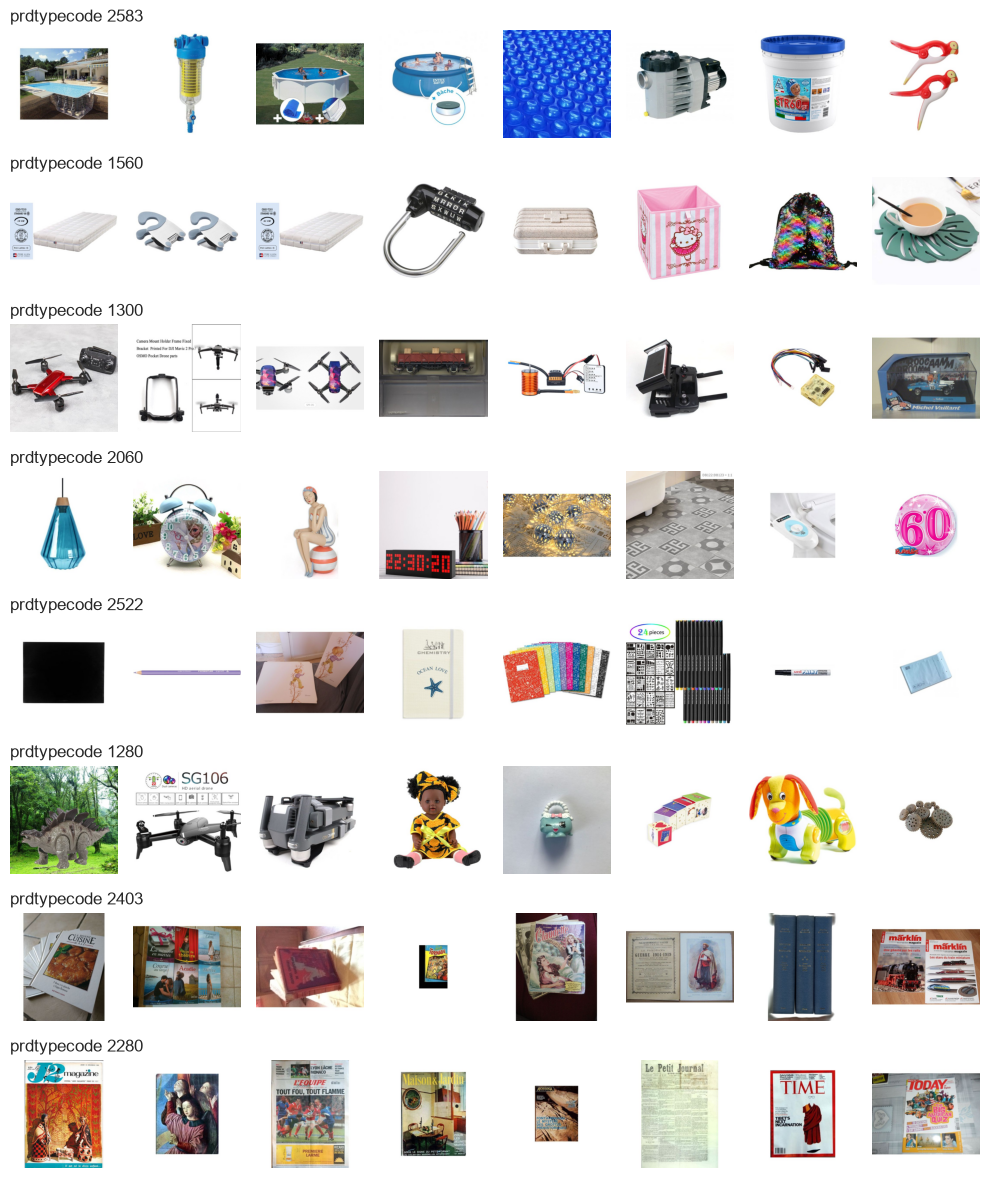

In [ ]:
selected_codes = (df["prdtypecode"].value_counts().head(8).index.tolist())

images_per_class = 8

fig, axes = plt.subplots(len(selected_codes), images_per_class,figsize=(10, 12))

for row_index, code_value in enumerate(selected_codes):

    candidates = df[(df["prdtypecode"] == code_value) & df["image_exists"]]

    sample_size = min(images_per_class, len(candidates))
    sample = candidates.sample(sample_size,random_state=42) if sample_size > 0 else candidates

    for col_index in range(images_per_class):

        ax = axes[row_index, col_index]
        ax.axis("off")

        if col_index < len(sample):
            item = sample.iloc[col_index]
            with Image.open(item["image_path"]) as image:
                ax.imshow(image.convert("RGB"))

        if col_index == 0:
            ax.set_title(
                f"prdtypecode {code_value}",
                loc="left"
            )

plt.tight_layout()
plt.show()

### Analysis

All **84916 products (100%)** have a matching image file, so no rows are missing an image.

Figure 9 shows that some classes have clear visual patterns. For example, the sampled images from class `2583` show swimming pools or pool equipment, while class `2522` mainly shows stationery products.

Other classes are more varied. Class `1560` contains visually different items, and drone like products appear in both classes `1300` and `1280`. This means that an image alone may not always be enough to distinguish the correct class.

The images contain useful class patterns, but some classes overlap. We will test image and combined models rather than relying on the samples alone.

## 8.2 Image readability and size

We test whether a random sample of 2000 images can be opened. We also record their size and colour mode.

In [375]:
image_sample = df.sample(2000, random_state=42)
image_records = []
failed_images = 0

for image_path in image_sample["image_path"]:
    try:
        with Image.open(image_path) as image:
            image.verify()
        with Image.open(image_path) as image:
            image_records.append({"Width": image.width, "Height": image.height, "Mode": image.mode})
    except Exception:
        failed_images += 1

image_audit = pd.DataFrame(image_records)
print(f"Readable images: {len(image_audit)} of {len(image_sample)}")
print(f"Failed images: {failed_images}")
display(image_audit.agg({"Width": ["min", "median", "max"], "Height": ["min", "median", "max"]}))
display(image_audit["Mode"].value_counts().to_frame("Images"))

Readable images: 2000 of 2000
Failed images: 0


,Width,Height
min,500.0,500.0
median,500.0,500.0
max,500.0,500.0


,Images
Mode,
RGB,2000


### Analysis

All **2000 sampled images** opened successfully. Every image is **500 × 500 pixels** and uses **RGB colour mode**.

The sampled format is consistent. The pipeline should still handle loading errors and resize images if the model requires it.

# 9. Data-quality Checks

Finally, we check for text-formatting problems and duplicated records. These checks help define the preprocessing steps and prevent unreliable model evaluation.

## 9.1 Text-quality checks

Product text collected from online sellers may contain HTML, web links, or incorrectly encoded characters. Counting these problems helps us decide what should be cleaned during preprocessing.

In [376]:
description_text = df["description"].fillna("").astype(str)
all_text = (
    df["designation"].fillna("").astype(str)
    + " "
    + description_text
)

text_quality = pd.DataFrame({
    "Issue": [
        "HTML tags",
        "Encoded HTML characters",
        "URLs",
        "Possible encoding problems",
    ],
    "Count": [
        description_text.str.contains(r"<[^>]+>", regex=True).sum(),
        description_text.str.contains(
            r"&(?:#\d+|#x[0-9A-Fa-f]+|[A-Za-z]+);", regex=True
        ).sum(),
        all_text.str.contains(
            r"https?://|www\.", case=False, regex=True
        ).sum(),
        all_text.str.contains(
            r"Ã.|Â.|â€|�", regex=True
        ).sum(),
    ],
})

text_quality["Percentage (%)"] = (
    text_quality["Count"] / len(df) * 100
).round(2)

display(text_quality)

,Issue,Count,Percentage (%)
0,HTML tags,15645,18.42
1,Encoded HTML characters,35030,41.25
2,URLs,203,0.24
3,Possible encoding problems,918,1.08


### Analysis

Encoded HTML characters appear in **35030 descriptions (41.25%)**. HTML tags occur in **15645 descriptions (18.42%)**. URLs and possible encoding problems affect **0.24%** and **1.08%** of products.

These findings support decoding HTML characters, removing HTML tags, and correcting obvious encoding problems during preprocessing. This cleaning should be applied carefully so that useful product words and numbers are preserved.

## 9.2 Duplicate checks

We check complete records and identifiers. We also compare designations after ignoring capitalisation, accents, punctuation and repeated spaces. The original text is not changed.

In [377]:
designation_normalized = (df["designation"].fillna("").str.normalize("NFKD").str.encode("ascii", errors="ignore").str.decode("ascii").str.lower())
designation_normalized = designation_normalized.str.replace(r"[^a-z0-9 ]", "", regex=True)
designation_normalized = designation_normalized.str.replace(r"\s+", " ", regex=True).str.strip()

duplicate_groups = pd.DataFrame({"Designation": designation_normalized, "Class": df["prdtypecode"]}).groupby("Designation").agg(Rows=("Designation", "size"), Classes=("Class", "nunique"))
repeated_groups = duplicate_groups[duplicate_groups["Rows"] > 1]
conflicting_groups = repeated_groups[repeated_groups["Classes"] > 1]

duplicate_summary = pd.Series({
    "Complete duplicate rows": df[["designation", "description", "productid", "imageid", "prdtypecode"]].duplicated().sum(),
    "Duplicated product IDs": df["productid"].duplicated().sum(),
    "Duplicated image IDs": df["imageid"].duplicated().sum(),
    "Repeated normalized designation groups": len(repeated_groups),
    "Products in repeated groups": int(repeated_groups["Rows"].sum()),
    "Groups containing different classes": len(conflicting_groups),
    "Products in conflicting groups": int(conflicting_groups["Rows"].sum()),
})

display(duplicate_summary.to_frame("Count"))

,Count
Complete duplicate rows,0
Duplicated product IDs,0
Duplicated image IDs,0
Repeated normalized designation groups,1470
Products in repeated groups,4187
Groups containing different classes,160
Products in conflicting groups,497


### Analysis

There are no duplicate records, product IDs or image IDs.

After normalisation, **4187 products** belong to **1470 repeated designation groups**. This is **4.93%** of the training data. **160 groups**, containing **497 products**, include more than one class.

Repeated names should not be removed automatically. They should be considered when splitting the data. The conflicting groups show that identical text can belong to different classes.

# 10. Pre-processing Strategy

We apply the main cleaning steps to three descriptions to show their effect.

## 10.1 Small text-cleaning example

In [382]:
from html import unescape
from src.text_utils import strip_html

def clean_text_example(text):
    decoded_text = unescape(unescape(text))
    text_without_tags = strip_html(decoded_text)
    return " ".join(text_without_tags.split())

example_text = df["description"].fillna("").astype(str)
has_html_noise = example_text.str.contains(r"<[^>]+>|&(?:#\d+|#x[0-9A-Fa-f]+|[A-Za-z]+);", regex=True)
cleaning_examples = example_text[has_html_noise].sample(3).to_frame("Before cleaning")
cleaning_examples["After cleaning"] = cleaning_examples["Before cleaning"].apply(clean_text_example)

display(cleaning_examples.apply(lambda column: column.str.slice(0, 300)))

,Before cleaning,After cleaning
5730,Tabouret snack style industriel avec assise blanche et pieds en métal chromé. Dimensions 3D (L x l x H): 515x52x101 cm<br /><br />Le tabouret snack BERLIN MINI présente de nombreux avantages séduisants ! Premièrement un style industriel qui ajout...,Tabouret snack style industriel avec assise blanche et pieds en métal chromé. Dimensions 3D (L x l x H): 515x52x101 cm Le tabouret snack BERLIN MINI présente de nombreux avantages séduisants ! Premièrement un style industriel qui ajoutera éléganc...
62305,1. Convient pour le générateur Honda gx120 gx160 GX200 - 2. Convient pour le générateur de 55 HP 65 HP - 3. Longueur du centre au centre du trou est de 160 mm - 4. Contenu de l&#39;emballage?: 1 x lanceur - 5. ouyfilter mettent l&#39;accent sur d...,1. Convient pour le générateur Honda gx120 gx160 GX200 - 2. Convient pour le générateur de 55 HP 65 HP - 3. Longueur du centre au centre du trou est de 160 mm - 4. Contenu de l'emballage?: 1 x lanceur - 5. ouyfilter mettent l'accent sur des produ...
48296,6pcs / set Moisissures Timbres Cartoon Outils Cookie Gâteau Décoration Cuisine Gadgets Accessoires Bakeware Fournitures Description du produit: 100% tout neuf et de haute qualité de conception exquise très attrayante. Il est apprécié pour sa faci...,6pcs / set Moisissures Timbres Cartoon Outils Cookie Gâteau Décoration Cuisine Gadgets Accessoires Bakeware Fournitures Description du produit: 100% tout neuf et de haute qualité de conception exquise très attrayante. Il est apprécié pour sa faci...


### Observation

Cleaning decodes characters, removes HTML tags and reduces repeated spaces. Product words, numbers and units remain.

This is only a small example. The final pipeline will apply the same steps to all text.

## 10.2 Proposed strategy

### Text

- Replace missing descriptions with an empty string instead of removing the product.
- Decode HTML characters and remove HTML tags.
- Correct clear encoding problems and remove unnecessary whitespace.
- Keep numbers, units, model names, and product codes at first because they may identify products.
- Compare models with and without French stopword removal.
- Compare description limits such as 34, 64, 128 and 256 words during modelling.

### Images

- Keep every product because all expected image files are available.
- Handle loading errors safely even though all 2000 sampled images were readable.
- Resize and normalize images according to the requirements of the chosen image model.
- Test simple image augmentation during training if it improves validation performance. Original validation images will remain unchanged.

### Data split and evaluation

- Preserve the class proportions when creating training and validation sets.
- Check repeated or nearly identical product text across the two sets.
- Report performance for individual classes as well as overall performance.
- Do not reduce the number of text or image features automatically. Dimension reduction will only be tested later if the feature size creates a clear memory or processing problem.

# 11. Main Findings

- The 27 classes contain between 764 and 10209 products. Class proportions should be preserved in the data split.
- Descriptions are missing for 35.09% of products and the rate reaches 97.36% in one class. These products should be kept.
- Designations have a median length of 11 words. Description length ranges from 1 to 2068 words.
- Designation and description lengths have a correlation of 0.265. The fields should be tested separately and together.
- The raw text contains HTML, encoded characters and common French words that need attention during preprocessing.
- Vocabulary differs by class, which supports testing a text model.
- All 84916 products have an image. All 2000 sampled files were readable 500 × 500 RGB images.
- Repeated normalised designation groups contain 4187 products. Groups with different classes contain 497 products.


# 12. Conclusion

Both text and images contain useful product information, but neither is sufficient in every case.

Designations are short and always available. Descriptions add detail but are missing for 35.09% of products. The text also needs HTML and encoding cleanup.

The two text fields have a weak length relationship. Some repeated designations also belong to different classes.

All products have an image. Some classes look distinct, while others overlap. Text may help with visually similar products.

The next report will compare designation, description, combined-text and image models using weighted F1-score. A combined model will then be tested.
